
---
# Curso: Data Mining - Semana 4

Docente: Soledad Espezúa (s.espezual@up.edu.pe)

---

<a name='manejoarchivos'></a>
# <font color=blue>Laboratorio de EDA con Seaborn</font>

**Objetivo:**
Realizar un análisis exploratorio inicial, seleccionando el gráfico según la **pregunta de análisis** y el **tipo de variables**, e interpretando los hallazgos de manera sustentada.

### Funciones que trabajaremos
1. `sns.histplot()`
2. `sns.boxplot()`
3. `sns.barplot()`
4. `sns.countplot()`
5. `sns.scatterplot()`
6. `sns.heatmap()`

> **pregunta → variables → gráfico → evidencia → hallazgo**.


<a name='seaborn'></a>
## <font color=blue>Visualización con SEABORN</font>

Seaborn es una libreria de visualización de alto nivel basada en matplotlib y ofrece 3 tipos de plots: **relacionales**, de **distribucion** y de **categorias**. Se puede generar los graficos a nivel:
* A nivel de **Figura**: las leyendas son generadas fuera del axes y tambien permite manejar grillas de axes (facetsplots y gridplots ).

* A nivel de **Axes**: las leyendas son generadas en el mismo axes.

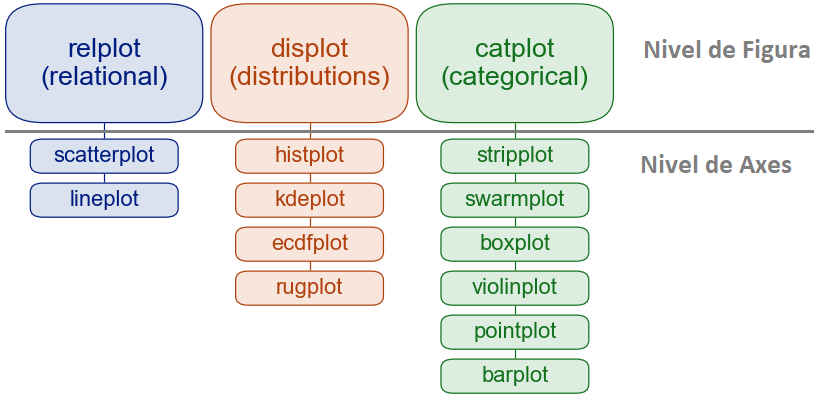

# <font color=green> Parte 1. Cargar e inspeccionar las fuentes</font>

<b>Data set penguins</b>

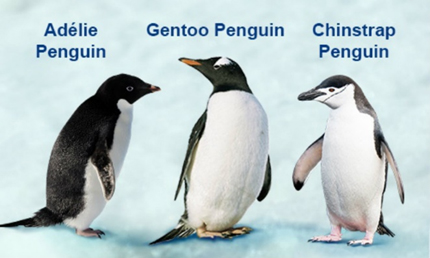

Este dataset contiene tres especies diferentes de pingüinos que se encontraron en tres islas que forman parte del archipiélago Palmer en la Antártida.



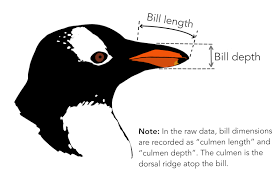





In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Estilo base
sns.set_theme(style="whitegrid")

# Cargar datos
df = pd.read_excel("Pinguinos.xlsx")

# Elimina una posible columna índice exportada desde Excel
df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]

display(df.head())
print("Dimensiones:", df.shape)
print("\nColumnas:")
df.columns.tolist()

# <font color=green>  1. ¿Qué tengo? Estructura del dataset</font>
Antes de graficar responda:

1. ¿Qué representa una fila?
2. ¿Qué variables son numéricas?
3. ¿Qué variables son categóricas?
4. ¿Existen valores faltantes?
5. ¿Qué categorías aparecen en `Especies`, `Isla` y `Sexo`?


In [ ]:
# Revise tipos de datos
display(df.dtypes.to_frame("tipo"))

# Revise valores faltantes
display(df.isna().sum().to_frame("faltantes"))

# Revise categorías principales
for col in ["Especies", "Isla", "Sexo"]:
    print(f"\n{col}")
    display(df[col].value_counts(dropna=False))


### Registro inicial


1.  **Unidad de análisis:**  
2.  
3.  
4.  
5.  


**Dos observaciones sobre la calidad o estructura de los datos:**

1.

2.

# <font color=green>  2. Histograma — distribución de una variable numérica</font>

**¿Cómo se distribuye el peso corporal (`Peso_g`)?**

Un histograma permite observar:
- forma;
- rango;
- concentración;
- sesgo;
- posibles valores extremos.


In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Peso_g",
    bins=20
)

plt.title("Distribución del peso corporal")
plt.xlabel("Peso (g)")
plt.ylabel("Frecuencia")
plt.show()

### Interpretación
No describa solo “hay barras”. Indique qué se observa en la distribución.

**Hallazgo:**  


# <font color=green> 3. Boxplot — comparar una variable numérica entre grupos</font>

**¿Cómo se distribuye el peso corporal entre las distintas especies?**

Aquí intervienen:
- una variable numérica: `Peso_g`;
- una variable categórica: `Especies`.

El boxplot permite comparar:
- mediana;
- dispersión;
- superposición entre grupos;
- posibles valores atípicos.


In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Especies",
    y="Peso_g"
)

plt.title("Peso corporal según especie")
plt.xlabel("Especie")
plt.ylabel("Peso (g)")
plt.show()


### Interpretación

**Hallazgo:**  


# <font color=green> 4. Barplot — un valor resumido por categoría</font>

**¿Cuál es el peso promedio de cada especie?**

`barplot()` resume una variable numérica dentro de cada categoría.

> En este ejemplo, la altura de la barra representa el **promedio de `Peso_g`**.


In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Especies",
    y="Peso_g",
    errorbar=None
)

plt.title("Peso promedio por especie")
plt.xlabel("Especie")
plt.ylabel("Peso promedio (g)")
plt.show()


### Interpretación

**Hallazgo:**  

**Pregunta de reflexión:** ¿qué información sobre dispersión se pierde si observamos solo los promedios?


# <font color=green>  5. Countplot — frecuencia de una variable categórica</font>

**¿Cuántos pingüinos hay registrados de cada especie?**

`countplot()` también se ve como un gráfico de barras, pero la altura representa **cantidad de observaciones**, no un promedio.


In [ ]:
from numpy import column_stack
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Especies"
)

plt.title("Número de observaciones por especie")
plt.xlabel("Especie")
plt.ylabel("Cantidad de pingüinos")

# Mostrar el número de observaciones encima de cada barra
ax.bar_label(ax.containers[0])

plt.show()

**Hallazgo**: La especie Adelie es la más representada en el dataset, con 152 observaciones, seguida de Gentoo con 124 y Chinstrap con 68. Por tanto, la muestra no está completamente balanceada entre especies; Chinstrap tiene considerablemente menos observaciones.

### Compare `barplot()` y `countplot()`

Complete:

- En `barplot()`, la altura representaba:  
- En `countplot()`, la altura representa:  
- ¿Por qué ambos gráficos pueden verse parecidos pero responder preguntas diferentes?  


# <font color=green>   6. Scatterplot — relación entre dos variables numéricas</font>

**¿Existe relación entre el largo de las alas y el peso corporal? ¿La relación cambia según la especie?**


In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Largo_alas_mm",
    y="Peso_g",
    hue="Especies"
)

plt.title("Relación entre largo de alas y peso corporal")
plt.xlabel("Largo de alas (mm)")
plt.ylabel("Peso (g)")
plt.show()


### Interpretación

Observe:
- dirección de la relación;
- agrupamientos;
- superposición entre especies;
- puntos aislados.

**Hallazgo:**  

> Recuerde: **asociación no implica causalidad**.


# <font color=green>   7. Heatmap — relaciones entre varias variables numéricas</font>

**¿Qué variables numéricas presentan las asociaciones lineales más fuertes?**


In [ ]:
# Seleccionar variables numéricas
numericas = df.select_dtypes(include="number")

# Calcular matriz de correlación
corr = numericas.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    center=0
)

plt.title("Matriz de correlación")
plt.show()


### Interpretación

Identifique:
- una asociación positiva relativamente fuerte;
- una asociación débil;
- una relación que valdría la pena explorar posteriormente.

**Hallazgo:**  


# <font color=blue>    TAREA </font>

- Formule y responda **dos preguntas nuevas** utilizando el dataset de pingüinos.
- Use **dos funciones diferentes** de las seis trabajadas.
- Una pregunta debe **comparar grupos**.
- La otra debe analizar una **relación entre variables**.
- Cada gráfico debe incluir:
  - título claro;
  - ejes correctamente etiquetados;
  - unidades cuando corresponda;
  - color solo cuando aporte información.

### Para cada pregunta presente:

**Pregunta de análisis:**  
**Variables involucradas y tipo:**  
**Gráfico elegido:**  
**¿Por qué este gráfico es adecuado?:**  
**Hallazgo sustentado en la evidencia del gráfico:**  



In [ ]:
# Tarea — gráfico 1


In [ ]:
# Tarea — gráfico 2
